Yuliia Chernysheva  
November 01, 2026  
CSC 2267

In [1]:
# import libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt;

# Data Ingestion & Overview
The dataset contains monthly employment statistics (Series ID: `LNS12000000`) extracted from the US Bureau of Labor Statistics (BLS).   
Values represent total non-farm employment in thousands of persons.

In [2]:
# Read the data from the file
df_employment_long = pd.read_excel("Employment long.xlsx", skiprows=11)
display(df_employment_long)

,Series ID,Year,Period,Value
0,LNS12000000,2012,M01,141584
1,LNS12000000,2012,M02,141858
2,LNS12000000,2012,M03,142036
3,LNS12000000,2012,M04,141899
4,LNS12000000,2012,M05,142206
...,...,...,...,...
118,LNS12000000,2021,M11,155324
119,LNS12000000,2021,M12,155975
120,LNS12000000,2022,M01,157174
121,LNS12000000,2022,M02,157722


In [3]:
# Check dataset information
display(df_employment_long.info())
print('-' * 40)

# Check the number of unique values in each column
print("Unique values: ")
display(df_employment_long.nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123 entries, 0 to 122
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Series ID  123 non-null    object
 1   Year       123 non-null    int64 
 2   Period     123 non-null    object
 3   Value      123 non-null    int64 
dtypes: int64(2), object(2)
memory usage: 4.0+ KB


None

----------------------------------------
Unique values: 


Series ID      1
Year          11
Period        12
Value        123
dtype: int64

# Data Cleaning & Annualization
Following the assignment guidelines:
- `For full years (2012-2021)`, annual employment is calculated as the 12-month arithmetic mean.
- `For 2022`, data is available only for January - March; the annual estimate is computed as the 3-month mean centered at February.

## Handling COVID-19 Outliers (2020–2021):
- **Case 0 (Base):** Uses the original annual data without changes.
- **Case 1:** Smooths the COVID-19 impact using linear interpolation between 2019 and 2022.
- **Case 2:** Excludes data after 2019 and uses only 2012–2019 to calculate the trend.

In [4]:
# Calculate annual employment: 12-month mean for 2012-2021, 
# 3-month mean for 2022
df_long = df_employment_long[['Year','Value']]
df_long = df_long.groupby('Year').mean().round().astype(int)

# Creation of baseline datasets (Case 0, Case 1, Case 2)
# Case 0: No adjustment for outliers
df_case0 = df_long.copy().reset_index()
display(df_case0)

# Case 1: Replace 2020-2021 outliers with NaN 
# and apply linear interpolation
df_case1 = df_long.copy().reset_index();
df_case1.loc[df_case1["Year"].isin([2020,2021]), "Value"] = np.nan
df_case1["Value"] = df_case1["Value"].interpolate().astype(int)
display(df_case1)

# Case 2: Truncate series to pre-COVID period (2012-2019)
df_case2 = df_long.copy().reset_index().query("Year < 2020")
display(df_case2)

,Year,Value
0,2012,142475
1,2013,143941
2,2014,146319
3,2015,148845
4,2016,151436
5,2017,153335
6,2018,155759
7,2019,157530
8,2020,147806
9,2021,152578


,Year,Value
0,2012,142475
1,2013,143941
2,2014,146319
3,2015,148845
4,2016,151436
5,2017,153335
6,2018,155759
7,2019,157530
8,2020,157615
9,2021,157700


,Year,Value
0,2012,142475
1,2013,143941
2,2014,146319
3,2015,148845
4,2016,151436
5,2017,153335
6,2018,155759
7,2019,157530


# Trendline Modeling & Visualization Function
Linear regression is used to find the best-fit line: $y = mx + b$  

Here, $x$ represents the year ($x = \text{Year} - 2011$), setting $2012 = 1, 2013 = 2, \dots, 2025 = 14$.  

The accuracy of the trendline is measured using $R^2$.

In [5]:
def show_plot(df, years_to_predict, suptitle_text, title_text):
    
    # Shift base year so that 2012 corresponds to x = 1
    shift_year = 2011
    
    # Set vertical axis display limits
    start_yticks = 125000
    end_yticks = 175000

    # Fit linear regression model (degree 1) and calculate R-squared
    slope, intercept = np.polyfit(df["Year"]-shift_year, df["Value"],1)
    r2 = np.corrcoef(df["Year"]-shift_year, df["Value"])[0,1] ** 2
 
    # Adding 3 years: Create a new array of years, 
    # ranging from the very first year in the data up to (the last year + 3)
    start_year = df["Year"].min()
    end_year_forecast = df["Year"].max() + years_to_predict
    x_trend = np.arange(start_year, end_year_forecast+1)

    # Calculate the trend line/forecast for all years
    y_trend = slope *  (x_trend-shift_year) + intercept
    
    # Create a plot
    plt.figure(figsize=(12,7))
    
    # Actual data (remain within their respective historical years)
    plt.plot(
        df["Year"], 
        df["Value"],
        label="Historical Data", 
        marker="o"
    )
    
    # Extended trendline (drawn based on an expanded dataset of years)
    plt.plot(
        x_trend, 
        y_trend,
        color = 'red',
        linestyle="--",
        linewidth=2,
        label=f"Trend & Forecast"
    )
    
    plt.suptitle(suptitle_text,
             fontsize=16, fontweight='bold')
    plt.title(title_text,
                fontsize=12, style="italic")
    
    plt.xticks([x for x in range(start_year, end_year_forecast+years_to_predict, 1)])
    ticks = range(start_yticks, end_yticks+1, 10000)
    plt.yticks(ticks, [f"{x:,.0f}" for x in ticks])
    
    plt.xlim(start_year - 0.5, end_year_forecast + 0.5)
    plt.ylim(start_yticks,end_yticks)
    
    plt.annotate(text=f"y = {slope:.1f}x + {intercept:.0f}\n$R^2$ = {r2:.4f}", 
                 xy=(0.10,0.88), 
                 xycoords='axes fraction',
                 fontsize=12,
                 va='top',
                 backgroundcolor='lightgray' 
                )
    
    plt.legend(fontsize=11, loc="lower right")
    plt.grid(True, axis='y', which="major", ls="--", alpha=0.5)
    plt.tight_layout()
    plt.box(False)
    plt.show()

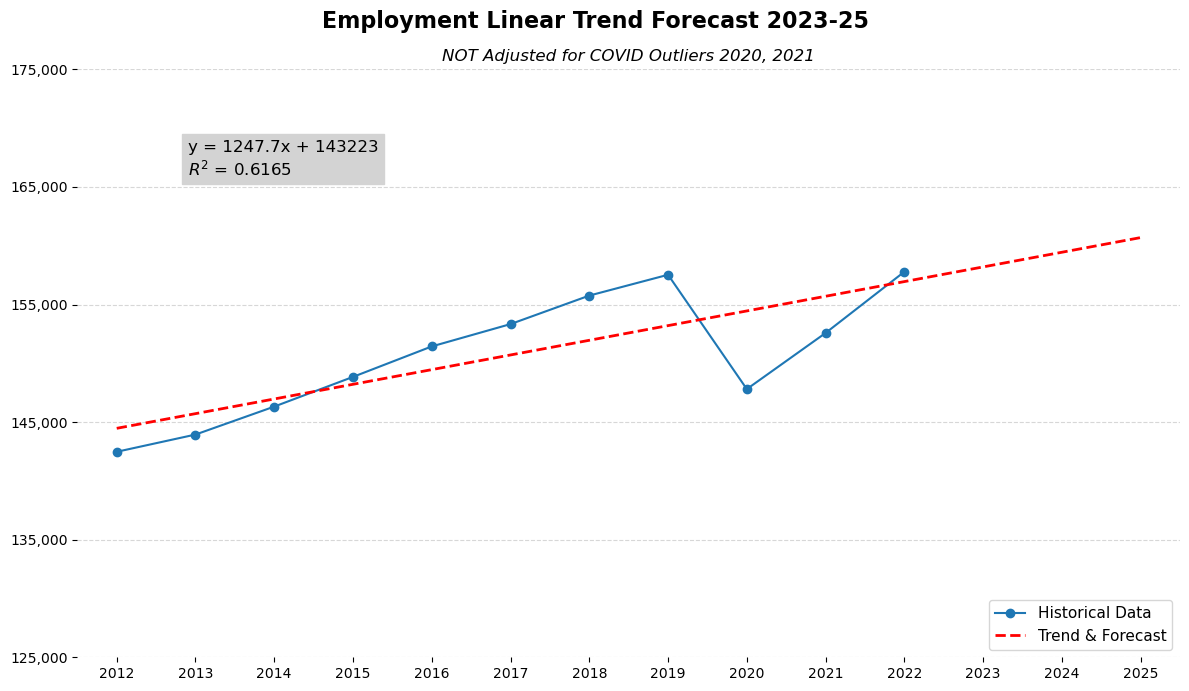

In [6]:
# Plot Case 0: Unadjusted historical trend and forecast
show_plot(df_case0, 3,
          'Employment Linear Trend Forecast 2023-25',
          'NOT Adjusted for COVID Outliers 2020, 2021')

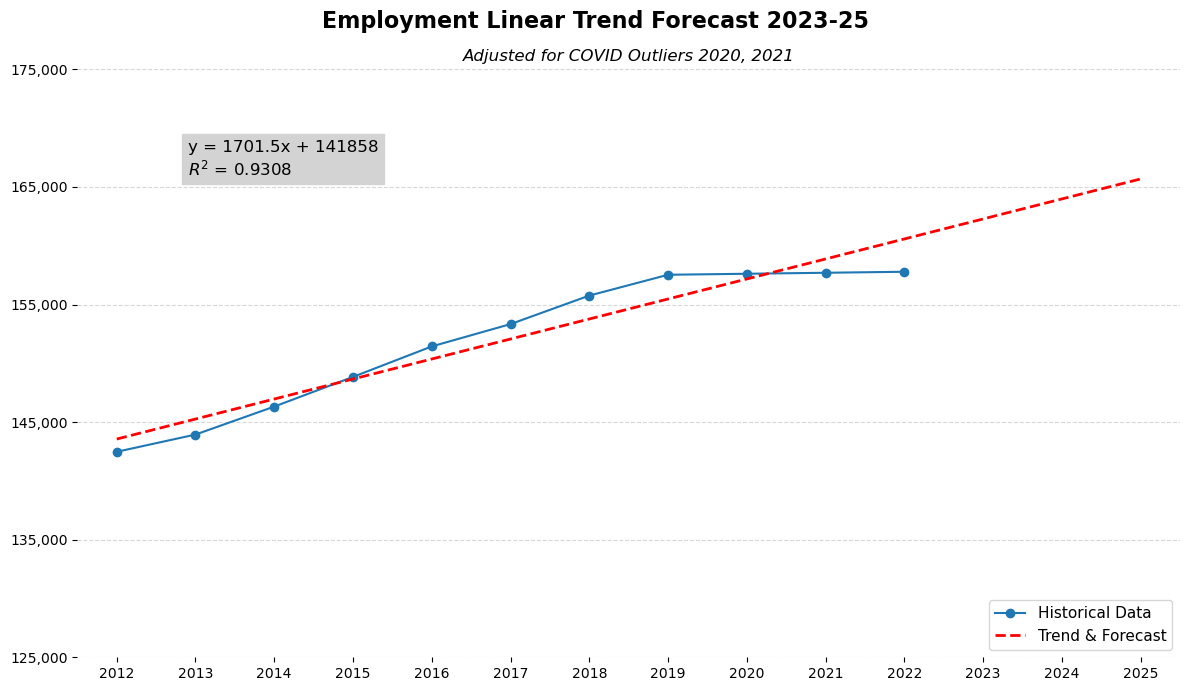

In [7]:
# Plot Case 1: Trend with COVID-19 outliers smoothed via interpolation
show_plot(df_case1, 3,
          'Employment Linear Trend Forecast 2023-25',
          'Adjusted for COVID Outliers 2020, 2021')

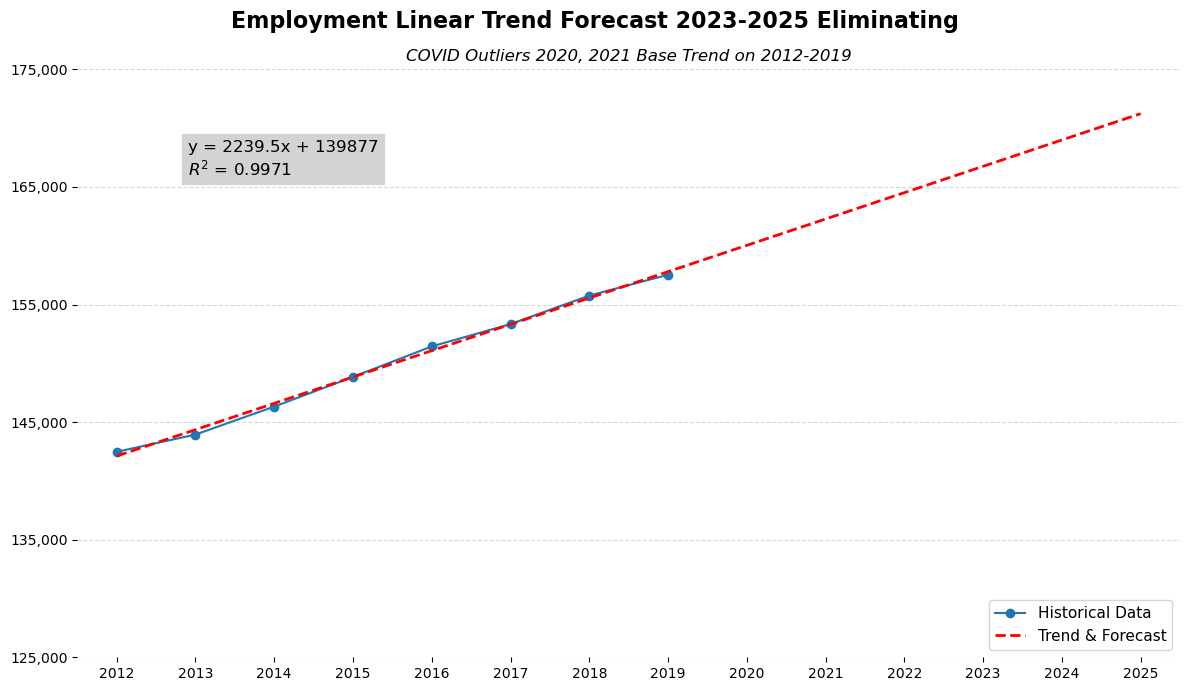

In [8]:
# Plot Case 2: Baseline trend based on pre-COVID data (2012-2019)
show_plot(df_case2, 6,
          'Employment Linear Trend Forecast 2023-2025 Eliminating',
          'COVID Outliers 2020, 2021 Base Trend on 2012-2019')

# 2023–2025 Forecasting & Comparative Analysis

Using the fitted regression equations, employment projections for 2023, 2024, and 2025 are evaluated across all three cases. 

Absolute and percentage differences against Base Case 0 are computed to assess the impact of outlier handling.

In [9]:
# Compute linear regression parameters and forecast employment values.
def get_case_forecast(df, years_forecast=[2023, 2024, 2025], shift_year=2011):    
    
    normalized_x = df["Year"] - shift_year
   
    # Linear regression (y = slope * x + intercept)
    slope, intercept = np.polyfit(normalized_x, df["Value"],1)
    
    # Coefficient of determination R^2
    r2 = np.corrcoef(normalized_x, df["Value"])[0,1] ** 2 

    # Forecast for 2023, 2024, 2025 (x = 12, 13, 14)
    x_pred = np.array(years_forecast) - shift_year
    y_pred = slope * x_pred + intercept
    
    return {
        "Trend Equation": f"y = {slope:.1f}x + {intercept:.0f}",
        "R2": r2,
        "year_2023": y_pred[0],
        "year_2024": y_pred[1],
        "year_2025": y_pred[2]
    }  

In [10]:
# Build consolidated forecast table for all three cases
forecast_df = pd.DataFrame.from_dict({
    "Base Case 0": get_case_forecast(df_case0),
    "Case 1": get_case_forecast(df_case1),
    "Case 2": get_case_forecast(df_case2)
}, orient="index")

pred_cols = ["year_2023", "year_2024", "year_2025"]
case0_pred = forecast_df.loc["Base Case 0", pred_cols]

# Calculate absolute differences against Base Case 0 (in thousands of workers)
diff_abs = pd.DataFrame({
    "Case 1": forecast_df.loc["Case 1", pred_cols] - case0_pred,
    "Case 2": forecast_df.loc["Case 2", pred_cols] - case0_pred
}).T

# Calculate percentage difference relative to Base Case 0
diff_pct = pd.DataFrame({
    "Case 1": 
    ((forecast_df.loc["Case 1", pred_cols] - case0_pred) / case0_pred * 100),
    "Case 2": 
    ((forecast_df.loc["Case 2", pred_cols] - case0_pred) / case0_pred * 100)
}).T

# Format and display summary tables matching assignment requirements
rename_columns = {
    'R2': 'R^2',
    'year_2023': 2023,
    'year_2024': 2024,
    'year_2025': 2025
}

print("2023-2025 Trend Forecasts:")
display(forecast_df.assign(
    R2=lambda df: df["R2"].map("{:.4f}".format),
    year_2023=lambda df: df['year_2023'].map('{:,.0f}'.format),
    year_2024=lambda df: df['year_2024'].map('{:,.0f}'.format),
    year_2025=lambda df: df['year_2025'].map('{:,.0f}'.format)
).rename(columns=rename_columns))

print("\nAbsolute Differences from Base Case 0 (thousands):")
display(diff_abs.assign(
    year_2023=lambda df: df['year_2023'].map('{:,.0f}'.format),
    year_2024=lambda df: df['year_2024'].map('{:,.0f}'.format),
    year_2025=lambda df: df['year_2025'].map('{:,.0f}'.format)
).rename(columns=rename_columns))

print("\nPercentage Differences from Base Case 0 (%):")
display(diff_pct.assign(
    year_2023=lambda df: df['year_2023'].map('{:.1f}%'.format),
    year_2024=lambda df: df['year_2024'].map('{:.1f}%'.format),
    year_2025=lambda df: df['year_2025'].map('{:.1f}%'.format)
).rename(columns=rename_columns))

2023-2025 Trend Forecasts:


,Trend Equation,R^2,2023,2024,2025
Base Case 0,y = 1247.7x + 143223,0.6165,"158,196","159,444","160,692"
Case 1,y = 1701.5x + 141858,0.9308,"162,276","163,978","165,679"
Case 2,y = 2239.5x + 139877,0.9971,"166,751","168,990","171,230"



Absolute Differences from Base Case 0 (thousands):


,2023,2024,2025
Case 1,"4,080","4,534","4,988"
Case 2,"8,555","9,546","10,538"



Percentage Differences from Base Case 0 (%):


,2023,2024,2025
Case 1,2.6%,2.8%,3.1%
Case 2,5.4%,6.0%,6.6%


# Summary & Analytical Discussion

## Interpretation of Results:

* **Base Case 0** ($R^2 = 0.6165$): Keeping the 2020 economic decline results in a weaker trendline ($m = 1247.7$) and lower employment forecasts.
   
* **Case 1 ($R^2 = 0.9308$):** Using linear interpolation to smooth the COVID-19 impact improves the trendline ($m = 1701.5$). Forecasts are 2.6% - 3.1% higher than Case 0.

   
* **Case 2 ($R^2 = 0.9971$):** Using only pre-COVID data produces the strongest fit ($m = 2239.5$). However, it assumes that employment growth continues at its pre-pandemic rate. The 2025 forecast reaches 171,230 thousand workers, 6.6% above Case 0.

## Conclusion:

Although Case 2 has the highest ($R^2 > 0.99$), it may be less reliable because it ignores post-pandemic changes. Case 1 offers the best balance by reducing the impact of COVID-19 while accounting for the economic recovery.